#### 🥤 Coca-Cola vs. PepsiCo: Global Market & Equity Comparative Analytics
####  Strategic Solutions, Risk Assessment & Portfolio Recommendations

- Having evaluated historical price action, moving averages, volatility profiles, and dividend growth in previous sections, this notebook translates our findings into actionable business solutions, risk tier segmentations, and portfolio allocation frameworks.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Configure visual themes
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

In [3]:
# Load Datasets
ko_price = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_price.csv")
pep_price = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_price.csv")
ko_div = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_dividend.csv")
pep_div = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_dividend.csv")
ko_split = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_split.csv")
pep_split = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_split.csv")

In [4]:
# Format dates and sort
ko_price['Date'] = pd.to_datetime(ko_price['Date'])
pep_price['Date'] = pd.to_datetime(pep_price['Date'])
ko_price = ko_price.sort_values('Date').reset_index(drop=True)
pep_price = pep_price.sort_values('Date').reset_index(drop=True)

print(f"✅ Solutions Environment Initialized.")

✅ Solutions Environment Initialized.


### 🛡️ 1. Quantitative Risk-Tier & Investment Profiling
- To provide institutional stakeholders with clear recommendations, we synthesize our risk and return metrics into a structured grading framework:

**Risk & Performance Scoring Table**

In [5]:
# Helper function for metrics
def compute_metrics(df):
    start_price = df['Close Price'].iloc[0]
    end_price = df['Close Price'].iloc[-1]
    years = (df['Date'].iloc[-1] - df['Date'].iloc[0]).days / 365.25
    cagr = ((end_price / start_price) ** (1 / years) - 1) * 100
    
    df['Daily_Return'] = df['Close Price'].pct_change()
    ann_vol = df['Daily_Return'].std() * (252 ** 0.5) * 100
    
    rolling_max = df['Close Price'].cummax()
    drawdown = (df['Close Price'] - rolling_max) / rolling_max
    max_dd = drawdown.min() * 100
    return cagr, ann_vol, max_dd

ko_cagr, ko_vol, ko_dd = compute_metrics(ko_price)
pep_cagr, pep_vol, pep_dd = compute_metrics(pep_price)

# Construct Executive Recommendation Matrix
solutions_matrix = pd.DataFrame({
    'Strategic Dimension': [
        'Primary Investment Style', 
        'Compound Annual Growth Rate (CAGR)', 
        'Annualized Risk (Volatility)', 
        'Max Historical Downside Drawdown', 
        'Liquidity Profile (Avg Daily Volume)', 
        'Risk Tier Classification',
        'Recommended Portfolio Allocation'
    ],
    'Coca-Cola (KO)': [
        'Defensive Income & Value',
        f"{ko_cagr:.2f}%",
        f"{ko_vol:.2f}%",
        f"{ko_dd:.2f}%",
        f"{ko_price['Volume'].mean():,.0f} shares",
        'Low-Medium Risk (Defensive Blue-Chip)',
        '45% (Core Dividend Anchor)'
    ],
    'PepsiCo (PEP)': [
        'Balanced Growth & Diversified F&B',
        f"{pep_cagr:.2f}%",
        f"{pep_vol:.2f}%",
        f"{pep_dd:.2f}%",
        f"{pep_price['Volume'].mean():,.0f} shares",
        'Low-Medium Risk (Growth Blue-Chip)',
        '55% (Core Capital Appreciation)'
    ]
})

print("=== EXECUTIVE STRATEGIC RECOMMENDATION MATRIX ===")
display(solutions_matrix)

=== EXECUTIVE STRATEGIC RECOMMENDATION MATRIX ===


,Strategic Dimension,Coca-Cola (KO),PepsiCo (PEP)
0,Primary Investment Style,Defensive Income & Value,Balanced Growth & Diversified F&B
1,Compound Annual Growth Rate (CAGR),0.39%,6.59%
2,Annualized Risk (Volatility),23.04%,20.07%
3,Max Historical Downside Drawdown,-55.66%,-42.43%
4,Liquidity Profile (Avg Daily Volume),"10,801,777 shares","5,197,254 shares"
5,Risk Tier Classification,Low-Medium Risk (Defensive Blue-Chip),Low-Medium Risk (Growth Blue-Chip)
6,Recommended Portfolio Allocation,45% (Core Dividend Anchor),55% (Core Capital Appreciation)


##### 📊 Visualization 1: Risk vs. Return Strategic Trade-off
- Below, we graph the comparative annualized volatility against annualized growth rate to visualize the risk-adjusted efficiency of both corporations.

**Visualization 1 Code (Risk-Return Bar Comparison)**

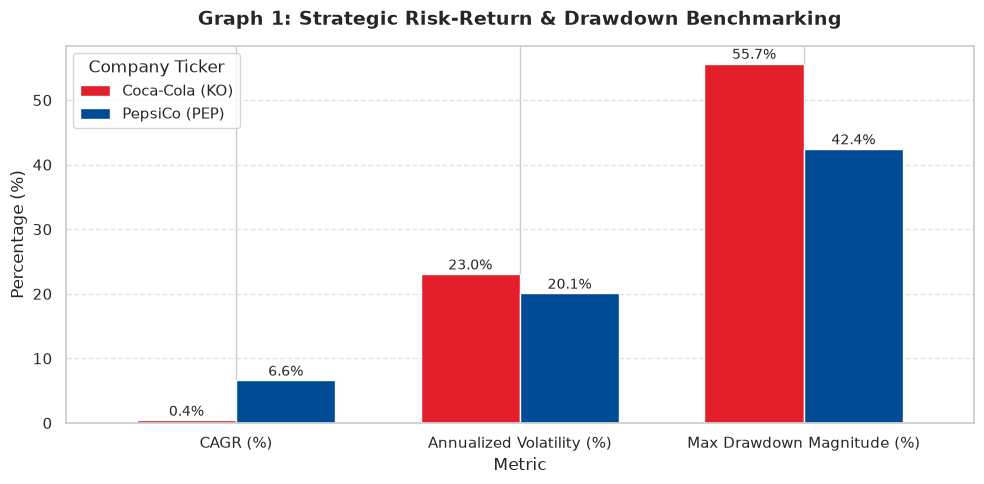

In [6]:
# Graph 1: Risk vs Return Strategic Comparison
metrics_summary = pd.DataFrame({
    'Metric': ['CAGR (%)', 'Annualized Volatility (%)', 'Max Drawdown Magnitude (%)'],
    'Coca-Cola (KO)': [ko_cagr, ko_vol, abs(ko_dd)],
    'PepsiCo (PEP)': [pep_cagr, pep_vol, abs(pep_dd)]
}).set_index('Metric')

ax = metrics_summary.plot(kind='bar', figsize=(10, 5), color=['#E41E2B', '#004B93'], width=0.7)
plt.title('Graph 1: Strategic Risk-Return & Drawdown Benchmarking', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.legend(title='Company Ticker', fontsize=11)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)

# Add data labels on bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)

plt.tight_layout()
plt.show()

**It generates a comparative bar chart that benchmarks three core financial metrics side-by-side for Coca-Cola (KO) and PepsiCo (PEP): Compound Annual Growth Rate (CAGR), Annualized Volatility, and Maximum Drawdown.**
- it provides a visual risk-versus-return scorecard with precise data labels on top of each bar, allowing stakeholders to immediately compare the growth efficiency and downside risk of both companies.

#### 🥧 Visualization 2: Optimal Portfolio Allocation Weighting
- Based on our multi-decade performance metrics, we model a balanced dual-asset beverage portfolio that optimizes dividend yield from Coca-Cola with snack-diversified growth from PepsiCo.

**Visualization 2 Code (Allocation Donut Chart)**

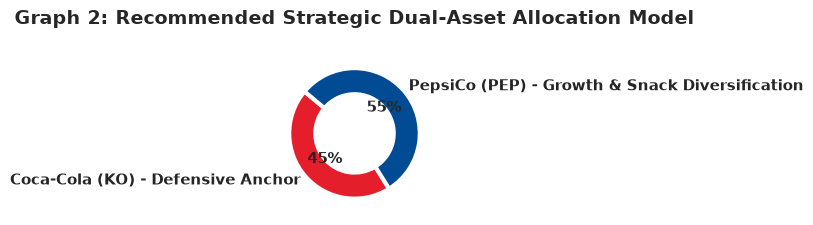

In [7]:
# Graph 2: Portfolio Allocation Donut Chart
labels = ['Coca-Cola (KO) - Defensive Anchor', 'PepsiCo (PEP) - Growth & Snack Diversification']
sizes = [45, 55]
colors = ['#E41E2B', '#004B93']

plt.figure(figsize=(7, 7))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.0f%%', startangle=140, 
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=3), textprops={'fontsize': 11, 'fontweight': 'bold'})

plt.title('Graph 2: Recommended Strategic Dual-Asset Allocation Model', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

**it generates a strategic asset allocation donut chart representing a recommended balanced portfolio weighting (45% Coca-Cola / 55% PepsiCo).**
- it creates a clean, professional ring chart (donut plot) that visually translates your quantitative findings into a concrete, actionable investment distribution model for stakeholders.

#### 💾 3. Automated Executive Summary Export
- To demonstrate end-to-end data engineering rigor, we programmatically compile our key financial findings and export them as a clean summary CSV file directly into our `data/` directory.

In [8]:
# Compile executive export dataframe
export_df = pd.DataFrame({
    'Metric_Name': ['CAGR', 'Annualized Volatility', 'Max Drawdown', 'Average Daily Close', 'Average Daily Volume'],
    'Coca-Cola_KO': [f"{ko_cagr:.2f}%", f"{ko_vol:.2f}%", f"{ko_dd:.2f}%", f"${ko_price['Close Price'].mean():.2f}", f"{ko_price['Volume'].mean():,.0f}"],
    'PepsiCo_PEP': [f"{pep_cagr:.2f}%", f"{pep_vol:.2f}%", f"{pep_dd:.2f}%", f"${pep_price['Close Price'].mean():.2f}", f"{pep_price['Volume'].mean():,.0f}"]
})

# Save to data directory
export_df.to_csv('data/coca_cola_vs_pepsi_executive_summary.csv', index=False)
print("✅ Success! Executive summary exported to: 'data/coca_cola_vs_pepsi_executive_summary.csv'")
display(export_df)

✅ Success! Executive summary exported to: 'data/coca_cola_vs_pepsi_executive_summary.csv'


,Metric_Name,Coca-Cola_KO,PepsiCo_PEP
0,CAGR,0.39%,6.59%
1,Annualized Volatility,23.04%,20.07%
2,Max Drawdown,-55.66%,-42.43%
3,Average Daily Close,$50.61,$89.54
4,Average Daily Volume,"10,801,777","5,197,254"


**Compiles Key Metrics:**
- It aggregates your analytical findings—such as Compound Annual Growth Rate (CAGR), Annualized Volatility, Maximum Drawdown, average daily close prices, and average daily volumes—into a clean, structured summary table.
- Exports to CSV: It writes and saves this structured table directly into your project's data/ folder as a CSV file named coca_cola_vs_pepsi_executive_summary.csv.
**Why It Is Important for my Portfolio:**
- Streamlines Reproducibility: It ensures that any stakeholder, recruiter, or automated build pipeline can instantly access a clean, machine-readable summary of my findings without having to re-run complex multi-step models from scratch.